In [1]:
import os
from io import StringIO
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# --- PATH CONFIGURATION ---
# Option A: Upload files directly to Colab -> set DATA_DIR = "/content"
# Option B: Mount Google Drive -> from google.colab import drive; drive.mount('/content/drive')
DATA_DIR = "/content"
OUT_DIR = "/content/outputs"
os.makedirs(OUT_DIR, exist_ok=True)

# Exact raw filenames mapped by Financial Year
FY_FILES = [
    ("FY22",     "2021-22",       "maker_stateCode_2021 TO 2022_all_records (1).csv", "State Wise and Fuel Data 21-22.csv", "Maker and Fuel Data 21-22.csv"),
    ("FY23",     "2022-23",       "maker_stateCode_2022 TO 2023_all_records.csv",     "State Wise and Fuel Data 22-23.csv", "Maker and Fuel Data 22-23.csv"),
    ("FY24",     "2023-24",       "maker_stateCode_2023 TO 2024_all_records (2).csv", "State Wise and Fuel Data 23-24.csv", "Maker and Fuel Data 23-24.csv"),
    ("FY25",     "2024-25",       "maker_stateCode_2024 TO 2025_all_records (3).csv", "State Wise and Fuel Data 24-25.csv", "Maker and Fuel Data 24-25.csv"),
    ("FY26",     "2025-26",       "maker_stateCode_2025 TO 2026_all_records.csv",     "State Wise and Fuel Data 25-26.csv", "Maker and Fuel Data 25-26.csv"),
    ("FY27_YTD", "2026-27 (YTD)", "maker_stateCode_2026 TO 2027_all_records.csv",     "State Wise and Fuel Data 26-27.csv", "Maker and Fuel Data 26-27.csv"),
]

# Corporate Chart Palette (Suzuki HQ Aesthetic)
SUZUKI_BLUE = "#003399"
TEAL        = "#0D9488"
AMBER       = "#D97706"
CORAL       = "#DC2626"
SLATE       = "#475569"
LIGHT_GRAY  = "#E2E8F0"
DARK_TEXT   = "#0F172A"

plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.edgecolor"] = "#CBD5E1"
plt.rcParams["axes.linewidth"] = 0.8

print("Configuration loaded. Output directory:", OUT_DIR)

Configuration loaded. Output directory: /content/outputs


In [2]:
# Map VAHAN's 34 granular fuel tags into 5 clean business powertrains
# Note: Mild hybrids (PETROL/HYBRID, PETROL(E20)/HYBRID) are grouped under Petrol per industry convention
FUEL_MAP = {
    "Petrol": [
        "PETROL", "PETROL(E20)", "PETROL/HYBRID", "PETROL(E20)/HYBRID"
    ],
    "Diesel": [
        "DIESEL", "DIESEL/HYBRID"
    ],
    "CNG_LPG": [
        "PETROL(E20)/CNG", "PETROL/CNG", "CNG ONLY", "BIO-CNG/BIO-GAS",
        "PETROL(E20)/LPG", "PETROL/LPG", "LPG ONLY",
        "PETROL(E20)/HYBRID/CNG", "PETROL/HYBRID/CNG",
        "DUAL DIESEL/CNG", "DUAL DIESEL/BIO CNG", "DUAL DIESEL/LNG",
        "HCNG", "LNG"
    ],
    "Strong_Hybrid": [
        "STRONG HYBRID EV", "PLUG-IN HYBRID EV"
    ],
    "EV": [
        "PURE EV", "ELECTRIC(BOV)"
    ]
}

def map_oem(maker_name: str) -> str:
    """Consolidate fragmented VAHAN legal registration entities into parent OEM groups."""
    n = str(maker_name).upper().strip()
    if "MARUTI SUZUKI" in n:
        return "Maruti Suzuki"
    elif "HYUNDAI MOTOR" in n:
        return "Hyundai"
    elif "TATA MOTORS" in n or "TATA PASSENGER" in n:
        return "Tata Motors"
    elif "MAHINDRA & MAHINDRA" in n or "MAHINDRA ELECTRIC" in n:
        return "Others" if "TRACTOR" in n else "Mahindra"
    elif "KIA INDIA" in n or "KIA MOTORS" in n:
        return "Kia"
    elif "TOYOTA KIRLOSKAR" in n:
        return "Toyota"
    elif "SKODA AUTO" in n or "VOLKSWAGEN" in n:
        return "Skoda-VW"
    elif "HONDA CARS" in n or "HONDA SIEL" in n:
        return "Honda"
    elif "MG MOTOR" in n or "JSW MG" in n:
        return "JSW MG"
    elif "RENAULT" in n:
        return "Renault"
    elif "NISSAN" in n:
        return "Nissan"
    elif "BYD" in n:
        return "BYD"
    elif "STELLANTIS" in n or "PCA AUTOMOBILES" in n or "FCA INDIA" in n:
        return "Stellantis"
    return "Others"

def read_maker_state_csv(filename: str) -> pd.DataFrame:
    """Read Maker x State CSV (banner on line 1, blank line 2, headers on line 3)."""
    path = os.path.join(DATA_DIR, filename)
    df = pd.read_csv(path, skiprows=2)
    df = df[df["Maker"].str.strip().str.lower() != "total"].copy()
    for col in df.columns:
        if col != "Maker":
            df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0)
    return df

def read_fuel_csv(filename: str, index_col: str) -> pd.DataFrame:
    """Read VAHAN Fuel exports, normalizing escaped literal '\\n' characters in headers."""
    path = os.path.join(DATA_DIR, filename)
    with open(path, "r", encoding="utf-8") as f:
        raw = f.read().replace("\\n", "\n")
    lines = [line for line in raw.splitlines() if line.strip()]
    df = pd.read_csv(StringIO("\n".join(lines[1:])))
    df = df[df[index_col].str.strip().str.lower() != "total"].copy()
    for col in df.columns:
        if col != index_col:
            df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0)
    return df

In [3]:
audit_rows = []

for fy_code, fy_label, ms_f, sf_f, mf_f in FY_FILES:
    df_ms = read_maker_state_csv(ms_f)
    df_sf = read_fuel_csv(sf_f, "State")
    df_mf = read_fuel_csv(mf_f, "Maker")

    tot_ms = int(df_ms["Total"].sum())
    tot_sf = int(df_sf["Total"].sum())
    tot_mf = int(df_mf["Total"].sum())
    reconciled = (tot_ms == tot_sf == tot_mf)

    audit_rows.append({
        "FY": fy_label,
        "States": len(df_sf),
        "Maker_x_State_Total": tot_ms,
        "State_x_Fuel_Total": tot_sf,
        "Maker_x_Fuel_Total": tot_mf,
        "Exact_Match": reconciled
    })

audit_df = pd.DataFrame(audit_rows)
print(audit_df.to_string(index=False))
print(f"\n6-Year Cumulative Reconciled PVs: {audit_df['Maker_x_State_Total'].sum():,}")
assert audit_df["Exact_Match"].all(), "Mismatch detected across VAHAN tables!"

           FY  States  Maker_x_State_Total  State_x_Fuel_Total  Maker_x_Fuel_Total  Exact_Match
      2021-22      36              3019645             3019645             3019645         True
      2022-23      36              3639126             3639126             3639126         True
      2023-24      36              3817374             3817374             3817374         True
      2024-25      36              3971509             3971509             3971509         True
      2025-26      36              4493554             4493554             4493554         True
2026-27 (YTD)      36              3101498             3101498             3101498         True

6-Year Cumulative Reconciled PVs: 22,042,706


In [4]:
oem_rows = []

for fy_code, fy_label, ms_f, sf_f, mf_f in FY_FILES:
    df_mf = read_fuel_csv(mf_f, "Maker")
    num_cols = [c for c in df_mf.columns if c != "Maker"]
    df_mf["OEM"] = df_mf["Maker"].apply(map_oem)

    # Aggregate raw fuel columns into 5 powertrains
    mapped_all = []
    for pt, cols in FUEL_MAP.items():
        valid = [c for c in cols if c in df_mf.columns]
        mapped_all.extend(valid)
        df_mf[pt] = df_mf[valid].sum(axis=1)

    other_cols = [c for c in num_cols if c not in mapped_all and c != "Total"]
    df_mf["Other_Fuel"] = df_mf[other_cols].sum(axis=1)

    grp = df_mf.groupby("OEM")[
        ["Petrol", "Diesel", "CNG_LPG", "Strong_Hybrid", "EV", "Other_Fuel", "Total"]
    ].sum().reset_index()

    ind_tot = grp["Total"].sum()
    grp["FY_Code"] = fy_code
    grp["Financial_Year"] = fy_label
    grp["Market_Share_Pct"] = (grp["Total"] / ind_tot * 100).round(2)

    for pt in ["Petrol", "Diesel", "CNG_LPG", "Strong_Hybrid", "EV"]:
        grp[f"{pt}_Mix_Pct"] = np.where(grp["Total"] > 0, (grp[pt] / grp["Total"] * 100).round(2), 0.0)
        seg_tot = grp[pt].sum()
        grp[f"{pt}_Seg_Share_Pct"] = np.where(seg_tot > 0, (grp[pt] / seg_tot * 100).round(2), 0.0)

    oem_rows.append(grp)

oem_master = pd.concat(oem_rows, ignore_index=True)
oem_cols = [
    "FY_Code", "Financial_Year", "OEM", "Total", "Market_Share_Pct",
    "Petrol", "Diesel", "CNG_LPG", "Strong_Hybrid", "EV", "Other_Fuel",
    "Petrol_Mix_Pct", "Diesel_Mix_Pct", "CNG_LPG_Mix_Pct", "Strong_Hybrid_Mix_Pct", "EV_Mix_Pct",
    "Petrol_Seg_Share_Pct", "Diesel_Seg_Share_Pct", "CNG_LPG_Seg_Share_Pct",
    "Strong_Hybrid_Seg_Share_Pct", "EV_Seg_Share_Pct"
]
oem_master = oem_master[oem_cols]
oem_master.to_csv(os.path.join(OUT_DIR, "Suzuki_India_PV_OEM_Yearly_Master.csv"), index=False)

print("Saved Suzuki_India_PV_OEM_Yearly_Master.csv ->", oem_master.shape)
oem_master[oem_master["OEM"] == "Maruti Suzuki"][
    ["Financial_Year", "Total", "Market_Share_Pct", "Petrol_Mix_Pct", "CNG_LPG_Mix_Pct", "Petrol_Seg_Share_Pct", "CNG_LPG_Seg_Share_Pct"]
]

Saved Suzuki_India_PV_OEM_Yearly_Master.csv -> (84, 21)


,Financial_Year,Total,Market_Share_Pct,Petrol_Mix_Pct,CNG_LPG_Mix_Pct,Petrol_Seg_Share_Pct,CNG_LPG_Seg_Share_Pct
6,2021-22,1280952,42.42,82.74,17.24,49.20,76.60
20,2022-23,1451441,39.88,82.04,17.95,47.17,68.56
34,2023-24,1480951,38.80,77.69,22.28,45.01,68.05
48,2024-25,1506737,37.94,71.04,28.07,44.53,66.26
62,2025-26,1671897,37.21,67.09,31.58,44.62,65.30
76,2026-27 (YTD),1175587,37.90,62.95,35.08,45.71,67.12


In [5]:
state_panel_rows = []

for fy_code, fy_label, ms_f, sf_f, mf_f in FY_FILES:
    df_ms = read_maker_state_csv(ms_f)
    state_cols = [c for c in df_ms.columns if c not in ["Maker", "Total"]]
    df_ms["OEM"] = df_ms["Maker"].apply(map_oem)
    oem_state = df_ms.groupby("OEM")[state_cols].sum()

    df_sf = read_fuel_csv(sf_f, "State").set_index("State")
    nat_tot = df_sf["Total"].sum()

    nat_pt_shares = {}
    for pt, cols in FUEL_MAP.items():
        valid = [c for c in cols if c in df_sf.columns]
        df_sf[pt] = df_sf[valid].sum(axis=1)
        nat_pt_shares[pt] = df_sf[pt].sum() / nat_tot

    for st in state_cols:
        st_tot = int(df_sf.loc[st, "Total"])
        get_oem = lambda name: int(oem_state.loc[name, st]) if name in oem_state.index else 0

        ms_vol = get_oem("Maruti Suzuki")
        row = {
            "FY_Code": fy_code,
            "Financial_Year": fy_label,
            "State": st,
            "Total_PVs": st_tot,
            "State_Vol_Share_Pct": round(st_tot / nat_tot * 100, 2) if nat_tot > 0 else 0.0,
            "Maruti_Vol": ms_vol,
            "Maruti_Share_Pct": round(ms_vol / st_tot * 100, 2) if st_tot > 0 else 0.0,
            "Hyundai_Share_Pct": round(get_oem("Hyundai") / st_tot * 100, 2) if st_tot > 0 else 0.0,
            "Tata_Share_Pct": round(get_oem("Tata Motors") / st_tot * 100, 2) if st_tot > 0 else 0.0,
            "Mahindra_Share_Pct": round(get_oem("Mahindra") / st_tot * 100, 2) if st_tot > 0 else 0.0,
            "Toyota_Share_Pct": round(get_oem("Toyota") / st_tot * 100, 2) if st_tot > 0 else 0.0,
        }
        for pt in ["Petrol", "Diesel", "CNG_LPG", "Strong_Hybrid", "EV"]:
            pt_vol = int(df_sf.loc[st, pt])
            pt_pct = (pt_vol / st_tot) if st_tot > 0 else 0.0
            row[pt] = pt_vol
            row[f"{pt}_Pct"] = round(pt_pct * 100, 2)
            # Location Quotient (Penetration Index > 1.2 = core cluster; < 0.7 = white space)
            row[f"{pt}_Penetration_Index"] = round(pt_pct / nat_pt_shares[pt], 2) if nat_pt_shares[pt] > 0 else 0.0

        state_panel_rows.append(row)

state_panel = pd.DataFrame(state_panel_rows)
state_panel.to_csv(os.path.join(OUT_DIR, "Suzuki_India_PV_State_Fuel_Panel.csv"), index=False)
print("Saved Suzuki_India_PV_State_Fuel_Panel.csv ->", state_panel.shape)

Saved Suzuki_India_PV_State_Fuel_Panel.csv -> (216, 26)


In [6]:
s22 = state_panel[state_panel["FY_Code"] == "FY22"].set_index("State")
s26 = state_panel[state_panel["FY_Code"] == "FY26"].set_index("State")
s27 = state_panel[state_panel["FY_Code"] == "FY27_YTD"].set_index("State")

nat_ms_26 = s26["Maruti_Vol"].sum() / s26["Total_PVs"].sum() * 100

strat_rows = []
for st in s26.index:
    v22 = s22.loc[st, "Total_PVs"]
    v26 = s26.loc[st, "Total_PVs"]
    cagr = ((v26 / v22) ** (1 / 4) - 1) * 100 if v22 > 0 else 0.0

    ms_sh_22 = s22.loc[st, "Maruti_Share_Pct"]
    ms_sh_26 = s26.loc[st, "Maruti_Share_Pct"]
    ms_sh_27 = s27.loc[st, "Maruti_Share_Pct"]
    delta_bps = int(round((ms_sh_26 - ms_sh_22) * 100, 0))

    if v26 < 75000:
        quad = "Tier-3 / Emerging Market (<75k PVs)"
    elif ms_sh_26 >= nat_ms_26 and v26 >= 200000:
        quad = "1. Core Stronghold (High Vol, High Share - Defend)"
    elif ms_sh_26 < nat_ms_26 and v26 >= 200000:
        quad = "2. Priority Attack Market (High Vol, Share Gap)"
    elif ms_sh_26 >= nat_ms_26:
        quad = "3. Mid-Size Fortress (Moderate Vol, High Share)"
    else:
        quad = "4. Selective Growth (Moderate Vol, Share Gap)"

    comp_shares = {
        "Hyundai": s26.loc[st, "Hyundai_Share_Pct"],
        "Tata Motors": s26.loc[st, "Tata_Share_Pct"],
        "Mahindra": s26.loc[st, "Mahindra_Share_Pct"],
        "Toyota": s26.loc[st, "Toyota_Share_Pct"]
    }
    top_rival = max(comp_shares, key=comp_shares.get)

    strat_rows.append({
        "State": st,
        "FY26_Total_PVs": v26,
        "PV_4Yr_CAGR_Pct": round(cagr, 2),
        "FY22_Maruti_Share_Pct": ms_sh_22,
        "FY26_Maruti_Share_Pct": ms_sh_26,
        "FY27_YTD_Maruti_Share_Pct": ms_sh_27,
        "Maruti_Share_Delta_FY22_26_bps": delta_bps,
        "Share_Gap_vs_National_bps": int(round((ms_sh_26 - nat_ms_26) * 100, 0)),
        "FY26_CNG_Pct": s26.loc[st, "CNG_LPG_Pct"],
        "FY26_CNG_Index": s26.loc[st, "CNG_LPG_Penetration_Index"],
        "FY26_EV_Pct": s26.loc[st, "EV_Pct"],
        "FY26_EV_Index": s26.loc[st, "EV_Penetration_Index"],
        "FY26_Strong_Hybrid_Pct": s26.loc[st, "Strong_Hybrid_Pct"],
        "FY26_Diesel_Pct": s26.loc[st, "Diesel_Pct"],
        "Top_Rival_OEM": top_rival,
        "Top_Rival_Share_Pct": comp_shares[top_rival],
        "Strategic_Quadrant": quad
    })

strat_matrix = pd.DataFrame(strat_rows).sort_values(by="FY26_Total_PVs", ascending=False)
strat_matrix.to_csv(os.path.join(OUT_DIR, "Suzuki_India_PV_State_Strategic_Matrix.csv"), index=False)

print("Saved Suzuki_India_PV_State_Strategic_Matrix.csv ->", strat_matrix.shape)
strat_matrix[["State", "FY26_Total_PVs", "FY26_Maruti_Share_Pct", "Share_Gap_vs_National_bps", "FY26_CNG_Pct", "FY26_EV_Pct", "Strategic_Quadrant"]].head(10)

Saved Suzuki_India_PV_State_Strategic_Matrix.csv -> (36, 17)


,State,FY26_Total_PVs,FY26_Maruti_Share_Pct,Share_Gap_vs_National_bps,FY26_CNG_Pct,FY26_EV_Pct,Strategic_Quadrant
1,Maharashtra,527817,31.99,-522,31.00,6.26,"2. Priority Attack Market (High Vol, Share Gap)"
25,Uttar Pradesh,499478,42.39,518,27.11,3.10,"1. Core Stronghold (High Vol, High Share - Def..."
16,Gujarat,386132,37.41,20,38.17,3.75,"1. Core Stronghold (High Vol, High Share - Def..."
3,Karnataka,313340,27.32,-989,4.92,7.48,"2. Priority Attack Market (High Vol, Share Gap)"
5,Tamil Nadu,299095,32.61,-460,4.03,5.58,"2. Priority Attack Market (High Vol, Share Gap)"
0,Haryana,291765,38.50,129,29.02,0.97,"1. Core Stronghold (High Vol, High Share - Def..."
4,Rajasthan,258539,40.18,297,25.95,5.22,"1. Core Stronghold (High Vol, High Share - Def..."
19,Kerala,248349,47.26,1005,1.86,8.31,"1. Core Stronghold (High Vol, High Share - Def..."
20,Madhya Pradesh,217106,40.50,329,25.61,2.90,"1. Core Stronghold (High Vol, High Share - Def..."
14,Delhi,197849,35.07,-214,27.65,8.33,"4. Selective Growth (Moderate Vol, Share Gap)"


In [7]:
# 1. National Powertrain Mix Evolution
ind_fuel = oem_master.groupby(["FY_Code", "Financial_Year"], sort=False)[
    ["Petrol", "Diesel", "CNG_LPG", "Strong_Hybrid", "EV", "Total"]
].sum().reset_index()

for pt in ["Petrol", "Diesel", "CNG_LPG", "Strong_Hybrid", "EV"]:
    ind_fuel[pt + "_Pct"] = (ind_fuel[pt] / ind_fuel["Total"] * 100).round(2)

print("=== 1. NATIONAL POWERTRAIN EVOLUTION (%) ===")
print(ind_fuel[["Financial_Year", "Total", "Petrol_Pct", "Diesel_Pct", "CNG_LPG_Pct", "Strong_Hybrid_Pct", "EV_Pct"]].to_string(index=False))

# 2. FY26 + FY27 YTD Segment Leadership (Including Petrol Leaderboard)
recent = oem_master[oem_master["FY_Code"].isin(["FY26", "FY27_YTD"])].groupby("OEM")[
    ["Petrol", "Diesel", "CNG_LPG", "Strong_Hybrid", "EV", "Total"]
].sum()

for col in ["Petrol", "CNG_LPG", "Strong_Hybrid", "EV"]:
    recent[col + "_Share_%"] = (recent[col] / recent[col].sum() * 100).round(2)

print("\n=== 2. SEGMENT LEADERSHIP (FY26 + FY27 YTD COMBINED) ===")
print(recent[["Total", "Petrol_Share_%", "CNG_LPG_Share_%", "Strong_Hybrid_Share_%", "EV_Share_%"]]
      .sort_values(by="Total", ascending=False).head(8).to_string())

# 3. Priority Attack Markets Volume Sum
attack_vol = strat_matrix[strat_matrix["Strategic_Quadrant"].str.startswith("2.")]["FY26_Total_PVs"].sum()
print(f"\nPriority Attack Markets (MH, KA, TN) FY26 Combined Volume: {attack_vol:,} PVs")

=== 1. NATIONAL POWERTRAIN EVOLUTION (%) ===
Financial_Year   Total  Petrol_Pct  Diesel_Pct  CNG_LPG_Pct  Strong_Hybrid_Pct  EV_Pct
       2021-22 3019645       71.34       18.48         9.55               0.00    0.62
       2022-23 3639126       69.36       18.99        10.44               0.00    1.20
       2023-24 3817374       66.97       18.01        12.70               0.04    2.26
       2024-25 3971509       60.53       18.67        16.07               2.01    2.71
       2025-26 4493554       55.94       18.80        18.00               2.45    4.78
 2026-27 (YTD) 3101498       52.20       18.03        19.81               2.19    7.77

=== 2. SEGMENT LEADERSHIP (FY26 + FY27 YTD COMBINED) ===
                 Total  Petrol_Share_%  CNG_LPG_Share_%  Strong_Hybrid_Share_%  EV_Share_%
OEM                                                                                       
Maruti Suzuki  2847484           45.05            66.08                  17.70        2.79
Tata Motors    

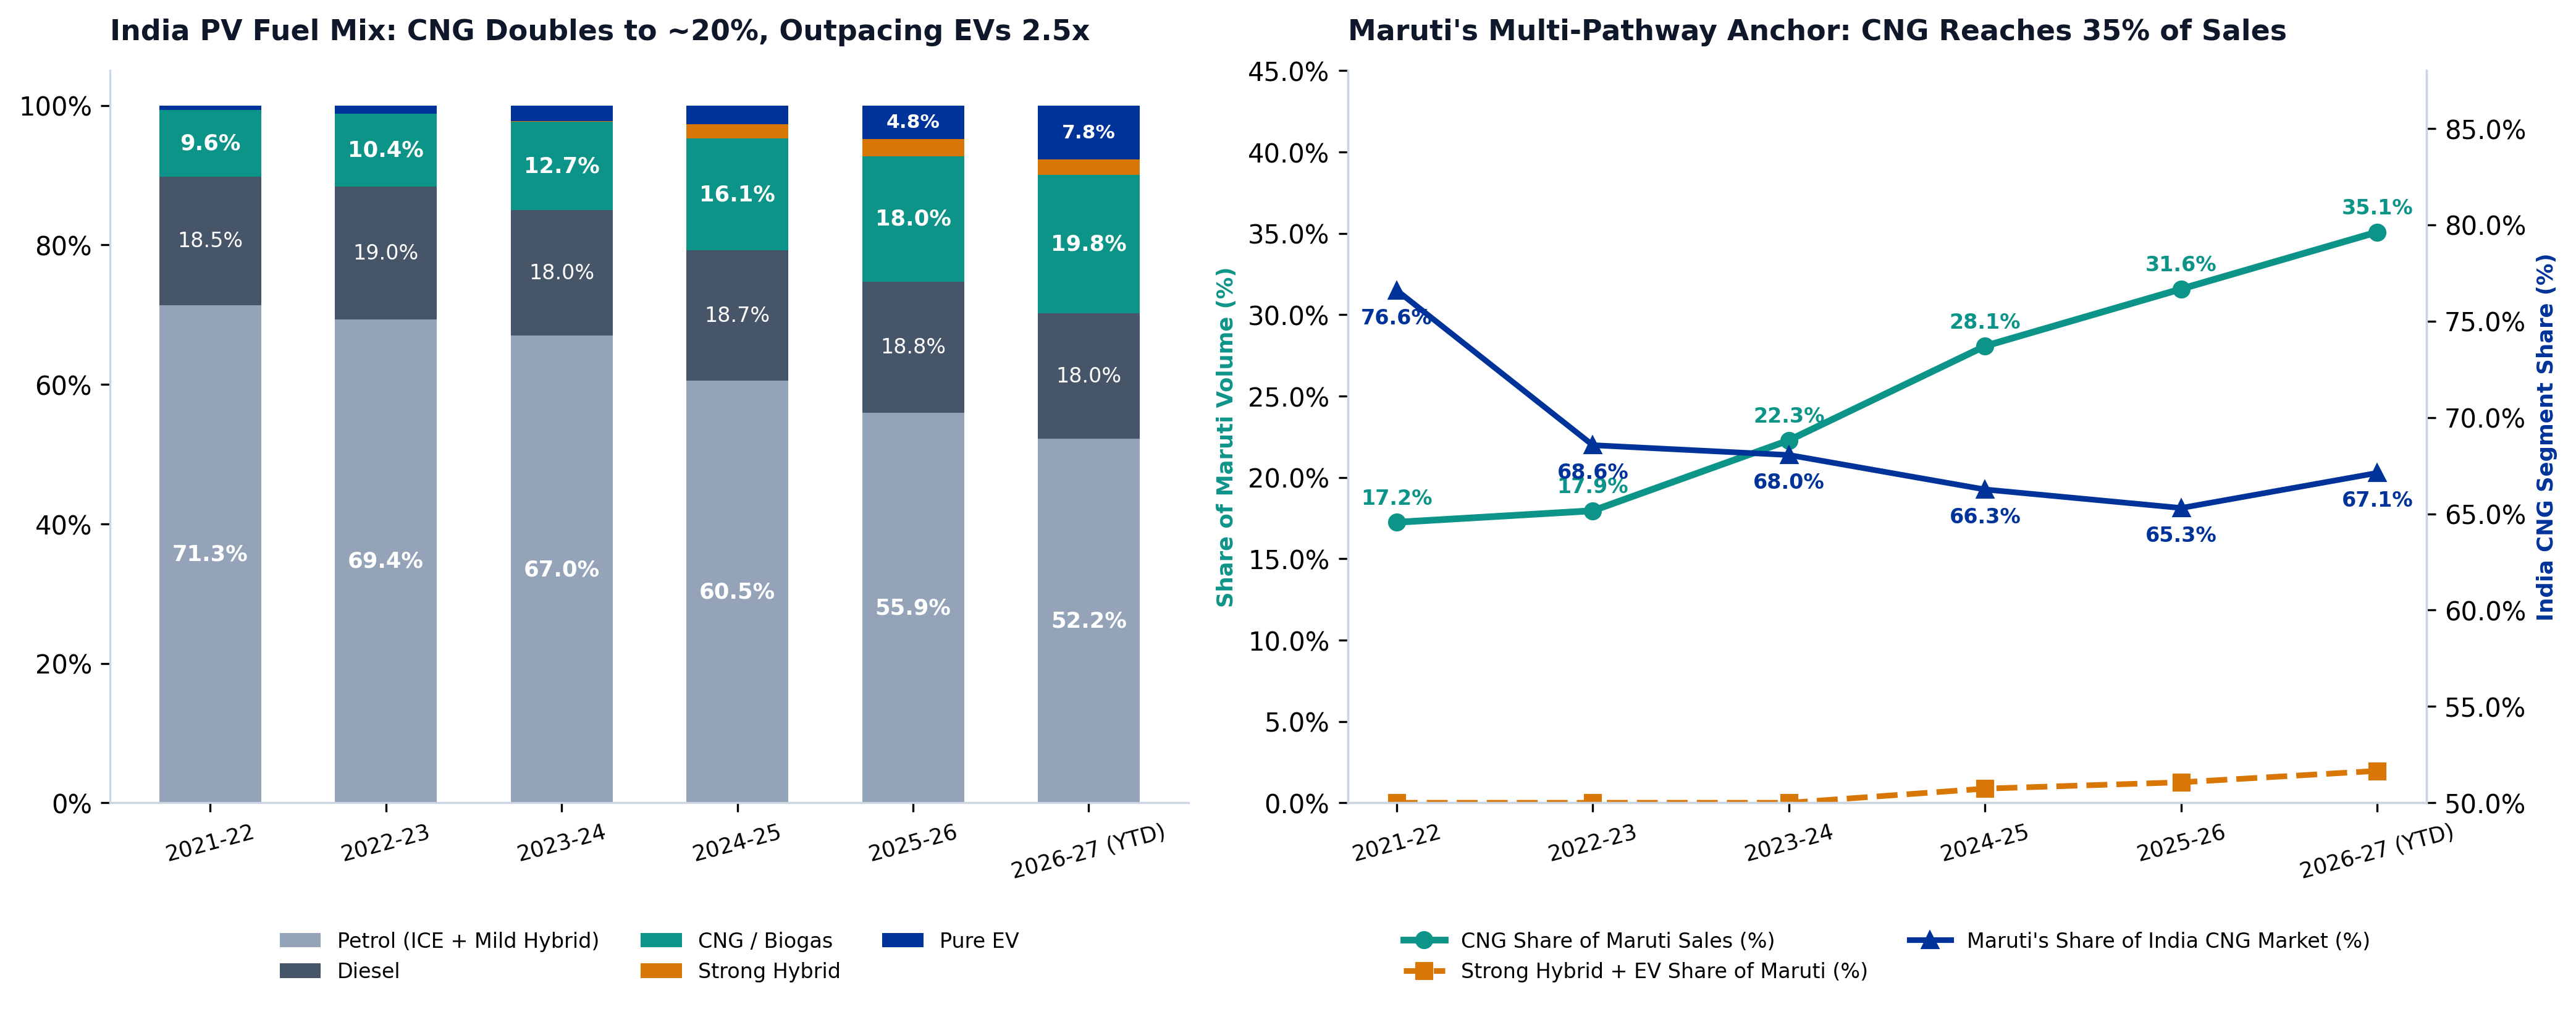

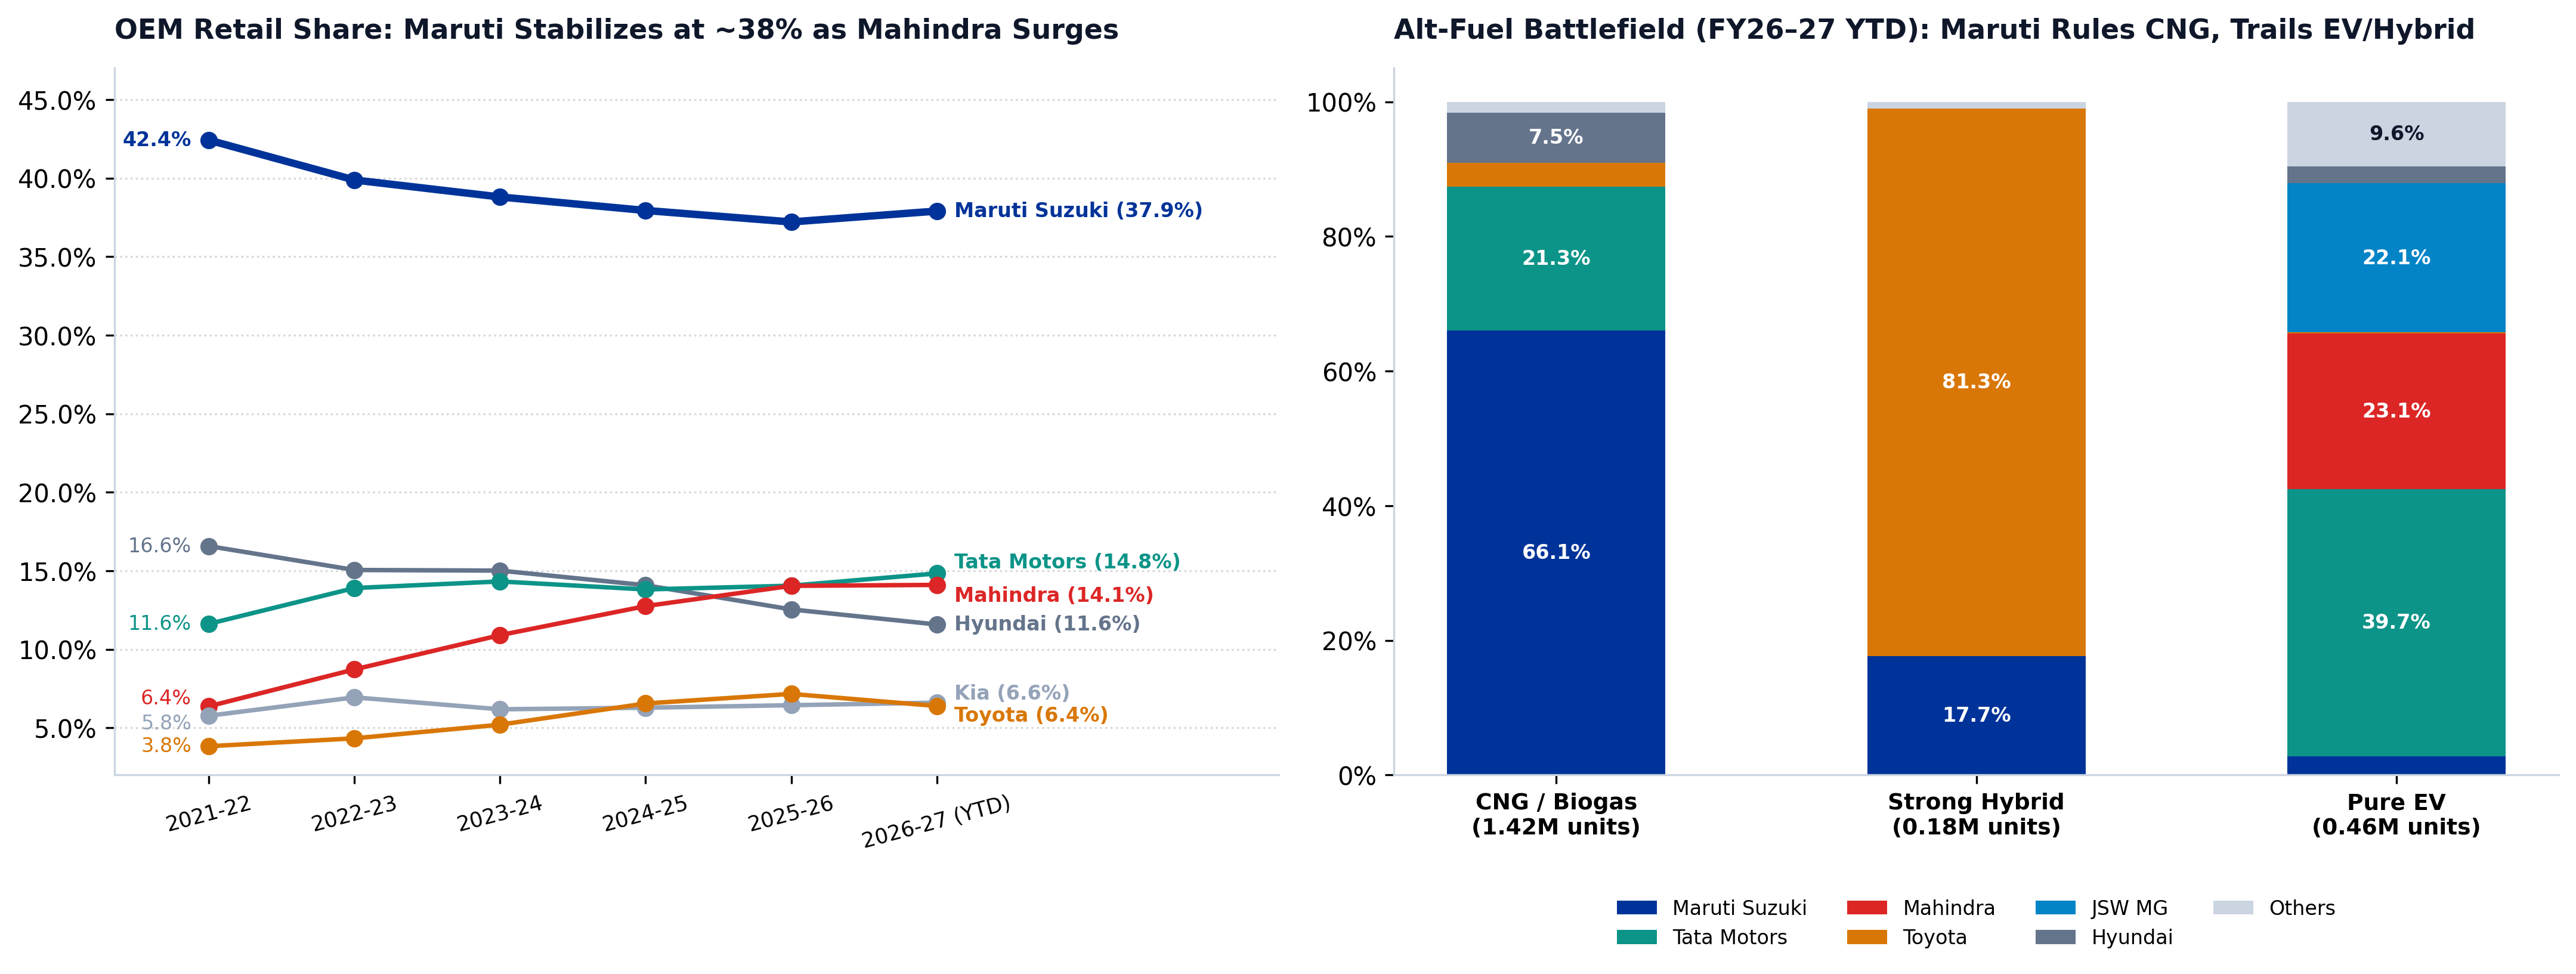

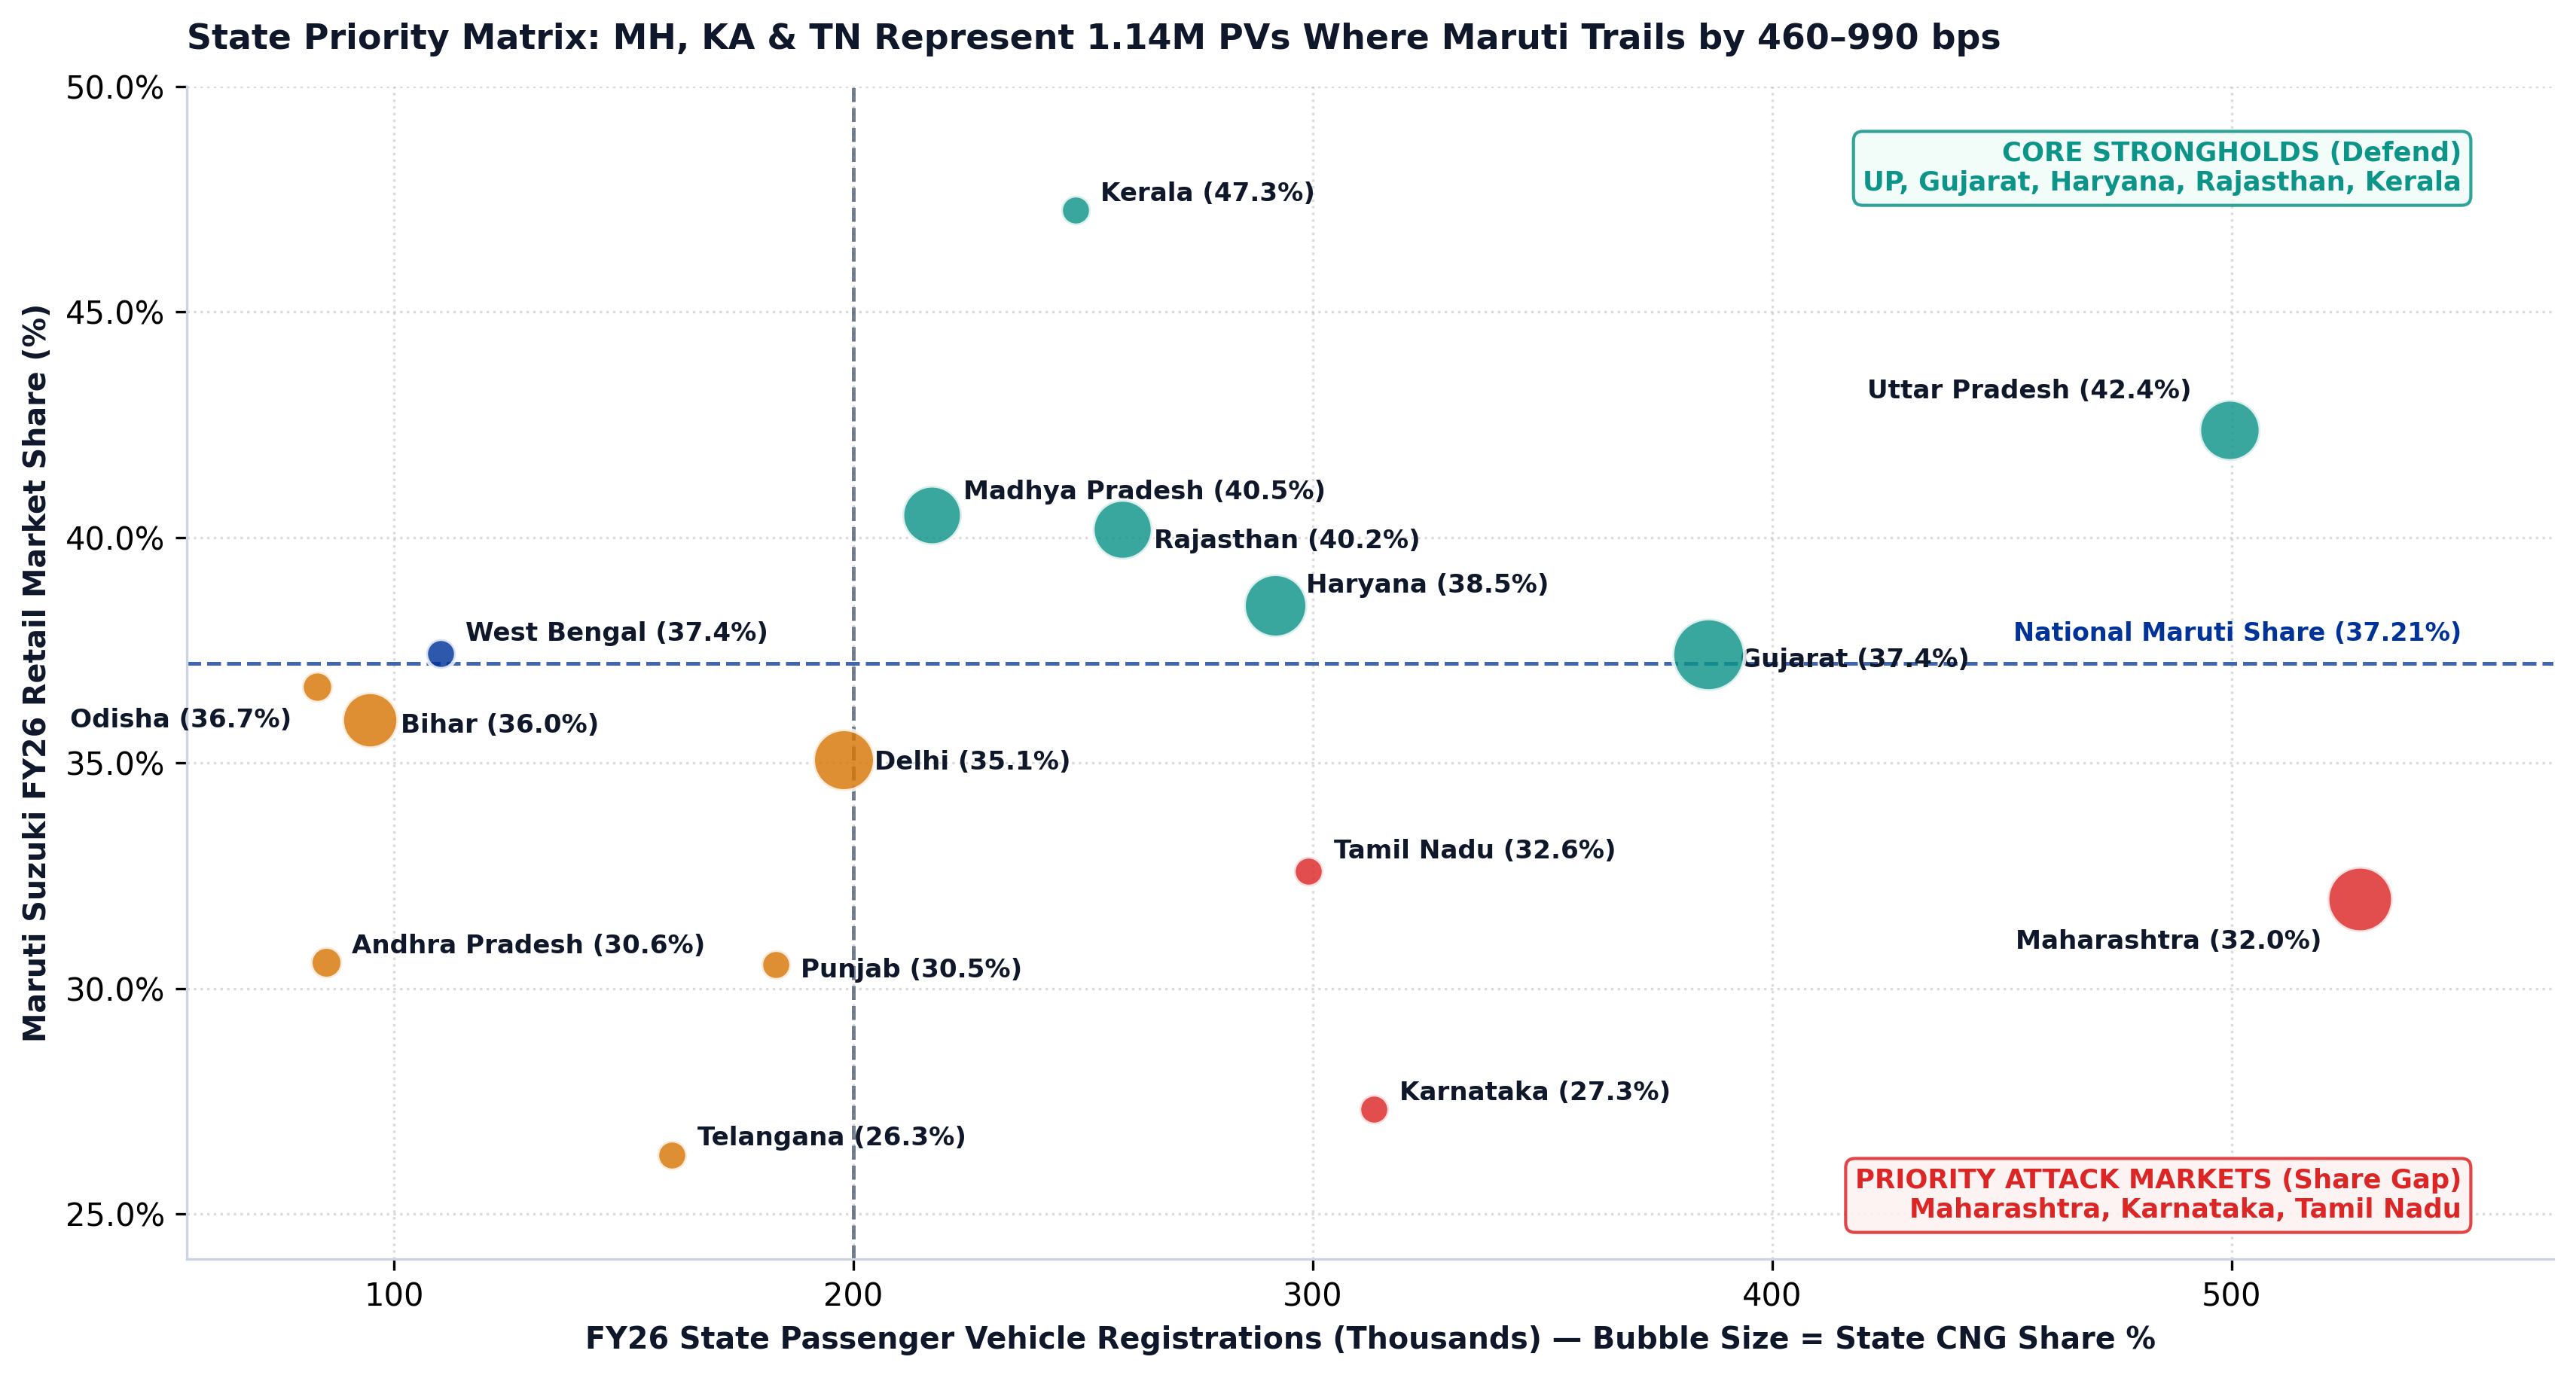

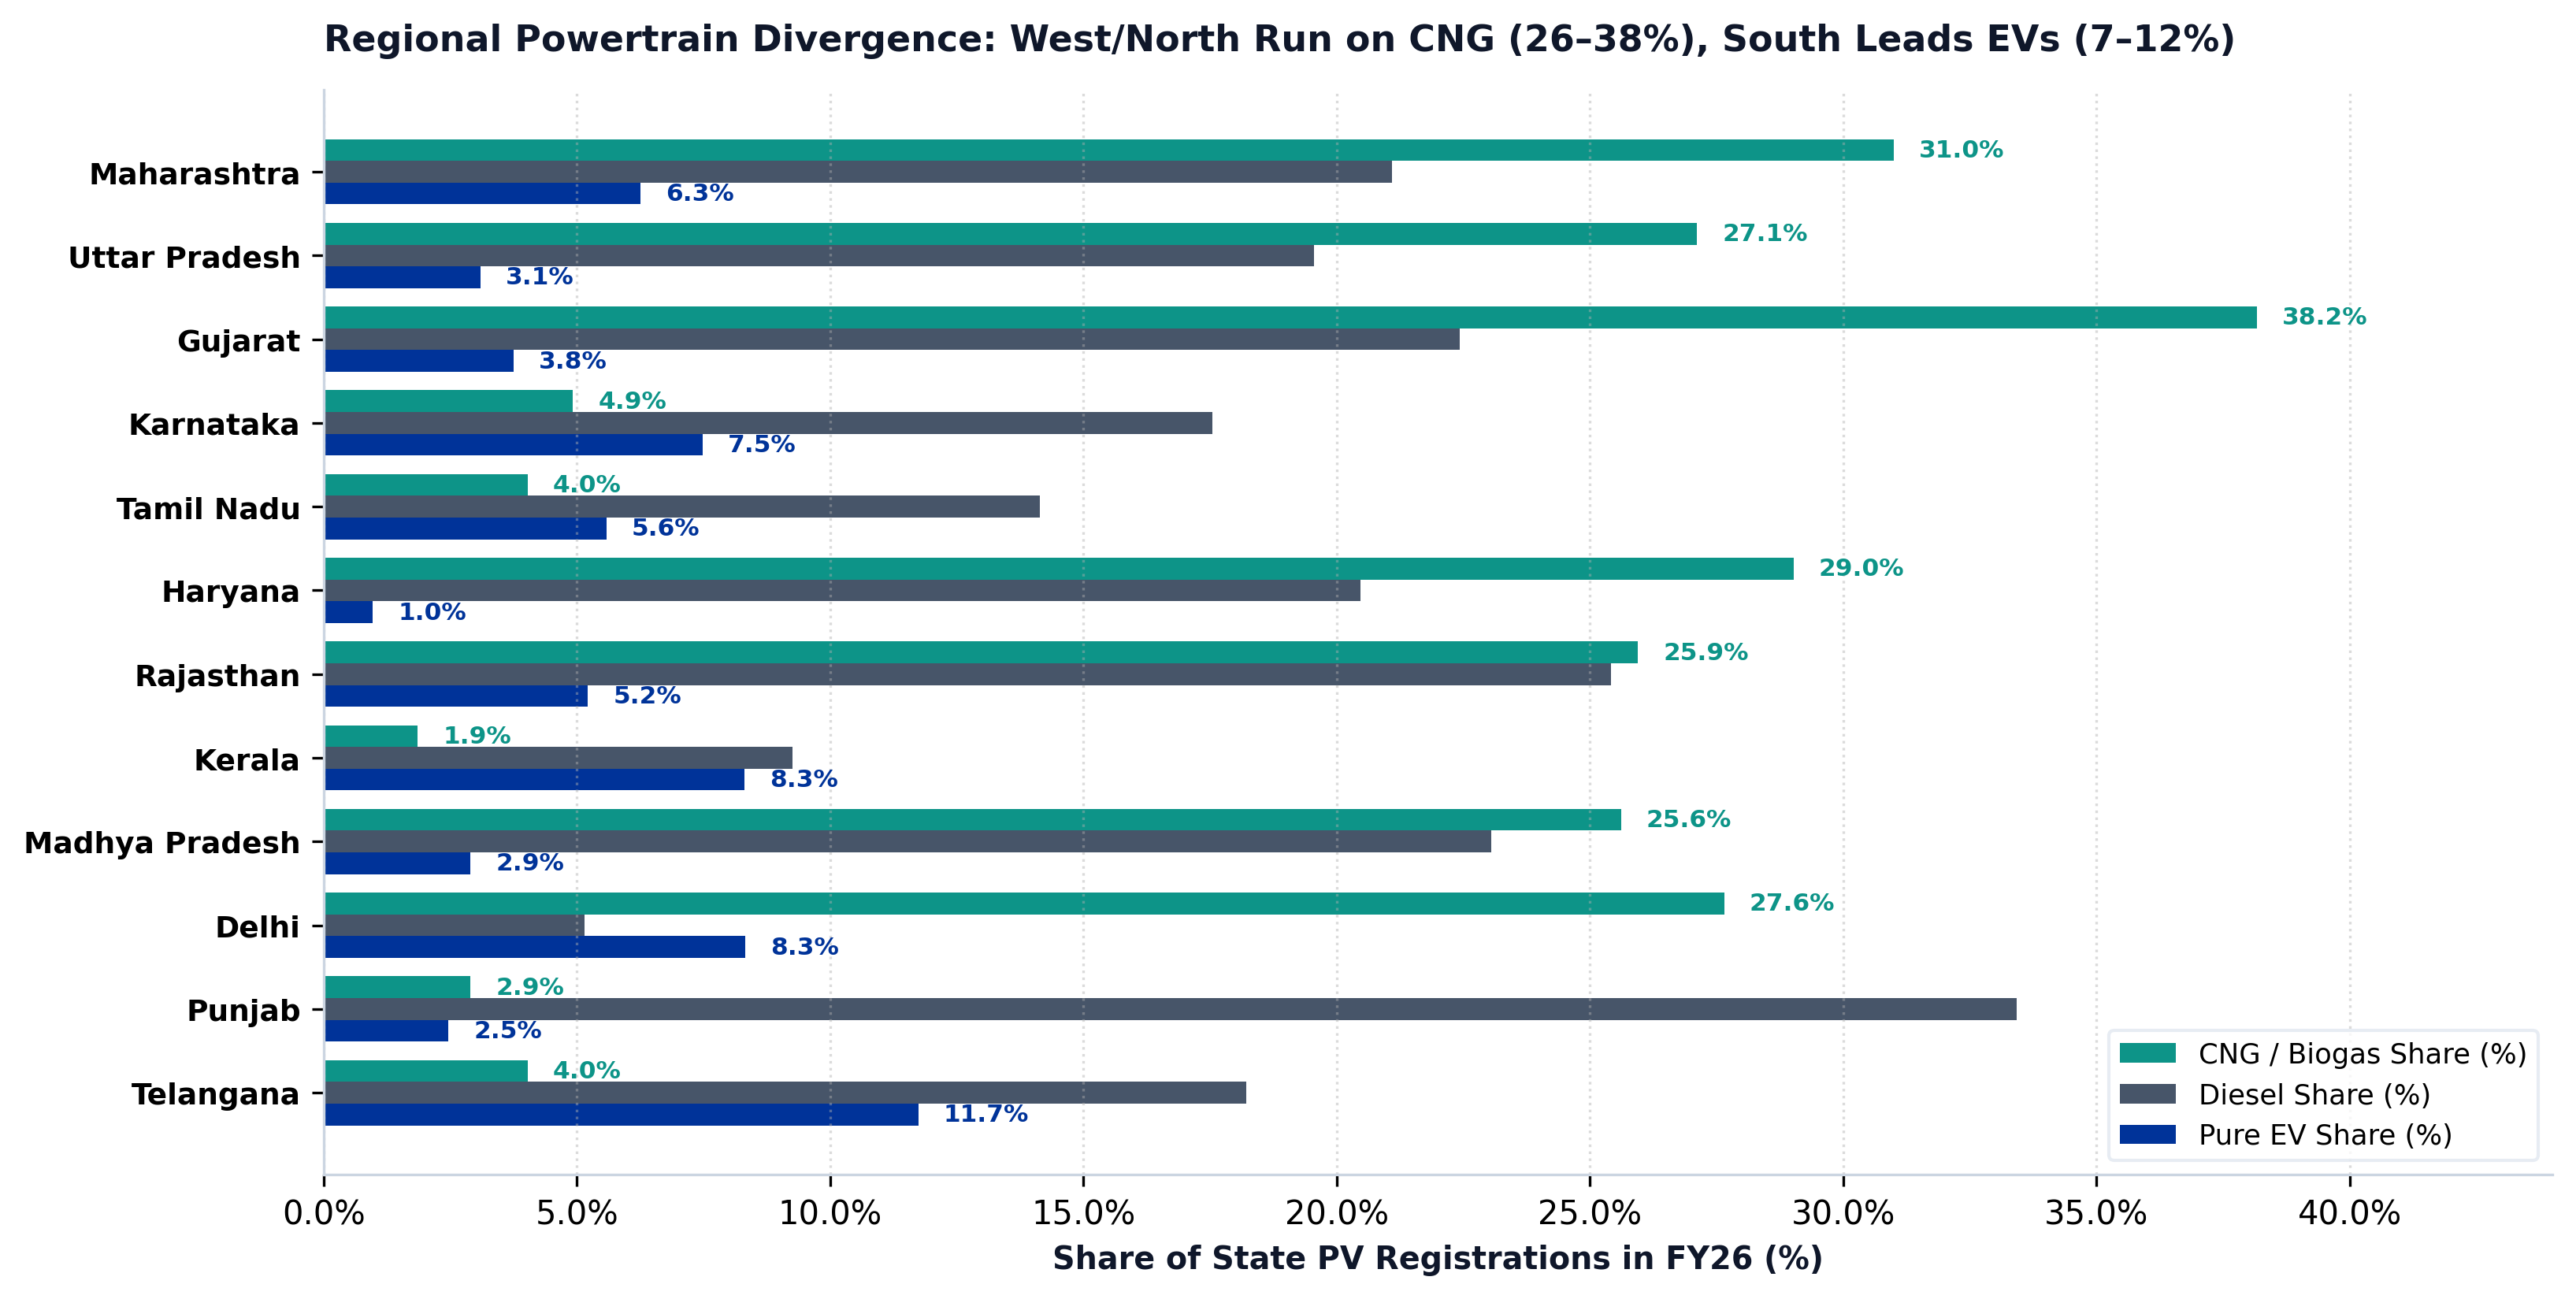

In [8]:
x = np.arange(len(ind_fuel))
labels = ind_fuel["Financial_Year"].tolist()

# --- CHART 1: Powertrain Transition & Maruti CNG Anchor ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.6), dpi=300)
fig.patch.set_facecolor("white")

b_pet, b_die = ind_fuel["Petrol_Pct"].values, ind_fuel["Diesel_Pct"].values
b_cng, b_sh, b_ev = ind_fuel["CNG_LPG_Pct"].values, ind_fuel["Strong_Hybrid_Pct"].values, ind_fuel["EV_Pct"].values

w = 0.58
ax1.bar(x, b_pet, width=w, label="Petrol (ICE + Mild Hybrid)", color="#94A3B8")
ax1.bar(x, b_die, width=w, bottom=b_pet, label="Diesel", color=SLATE)
ax1.bar(x, b_cng, width=w, bottom=b_pet+b_die, label="CNG / Biogas", color=TEAL)
ax1.bar(x, b_sh,  width=w, bottom=b_pet+b_die+b_cng, label="Strong Hybrid", color=AMBER)
ax1.bar(x, b_ev,  width=w, bottom=b_pet+b_die+b_cng+b_sh, label="Pure EV", color=SUZUKI_BLUE)

for i in range(len(x)):
    ax1.text(x[i], b_pet[i]/2, f"{b_pet[i]:.1f}%", ha="center", va="center", color="white", fontweight="bold", fontsize=8.5)
    ax1.text(x[i], b_pet[i] + b_die[i]/2, f"{b_die[i]:.1f}%", ha="center", va="center", color="white", fontsize=8)
    ax1.text(x[i], b_pet[i] + b_die[i] + b_cng[i]/2, f"{b_cng[i]:.1f}%", ha="center", va="center", color="white", fontweight="bold", fontsize=8.5)
    if b_ev[i] >= 4.0:
        ax1.text(x[i], b_pet[i] + b_die[i] + b_cng[i] + b_sh[i] + b_ev[i]/2, f"{b_ev[i]:.1f}%", ha="center", va="center", color="white", fontweight="bold", fontsize=7.5)

ax1.set_xticks(x); ax1.set_xticklabels(labels, fontsize=8.5, rotation=15)
ax1.set_ylim(0, 105); ax1.yaxis.set_major_formatter(mtick.PercentFormatter())
ax1.set_title("India PV Fuel Mix: CNG Doubles to ~20%, Outpacing EVs 2.5x", fontsize=11, fontweight="bold", color=DARK_TEXT, pad=12, loc="left")
ax1.spines["top"].set_visible(False); ax1.spines["right"].set_visible(False)
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False, fontsize=8)

ms_df = oem_master[oem_master["OEM"] == "Maruti Suzuki"].reset_index(drop=True)
ax2.plot(x, ms_df["CNG_LPG_Mix_Pct"], marker="o", linewidth=2.6, color=TEAL, label="CNG Share of Maruti Sales (%)")
ax2.plot(x, ms_df["Strong_Hybrid_Mix_Pct"] + ms_df["EV_Mix_Pct"], marker="s", linewidth=2.2, linestyle="--", color=AMBER, label="Strong Hybrid + EV Share of Maruti (%)")
ax2_twin = ax2.twinx()
ax2_twin.plot(x, ms_df["CNG_LPG_Seg_Share_Pct"], marker="^", linewidth=2.2, color=SUZUKI_BLUE, label="Maruti's Share of India CNG Market (%)")

for i in range(len(x)):
    ax2.annotate(f"{ms_df.loc[i, 'CNG_LPG_Mix_Pct']:.1f}%", (x[i], ms_df.loc[i, "CNG_LPG_Mix_Pct"]), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8, fontweight="bold", color=TEAL)
    ax2_twin.annotate(f"{ms_df.loc[i, 'CNG_LPG_Seg_Share_Pct']:.1f}%", (x[i], ms_df.loc[i, "CNG_LPG_Seg_Share_Pct"]), textcoords="offset points", xytext=(0, -13), ha="center", fontsize=8, fontweight="bold", color=SUZUKI_BLUE)

ax2.set_xticks(x); ax2.set_xticklabels(labels, fontsize=8.5, rotation=15)
ax2.set_ylim(0, 45); ax2_twin.set_ylim(50, 88)
ax2.yaxis.set_major_formatter(mtick.PercentFormatter()); ax2_twin.yaxis.set_major_formatter(mtick.PercentFormatter())
ax2.set_ylabel("Share of Maruti Volume (%)", fontsize=8.5, color=TEAL, fontweight="bold")
ax2_twin.set_ylabel("India CNG Segment Share (%)", fontsize=8.5, color=SUZUKI_BLUE, fontweight="bold")
ax2.set_title("Maruti's Multi-Pathway Anchor: CNG Reaches 35% of Sales", fontsize=11, fontweight="bold", color=DARK_TEXT, pad=12, loc="left")
ax2.spines["top"].set_visible(False); ax2_twin.spines["top"].set_visible(False)

l1, lb1 = ax2.get_legend_handles_labels(); l2, lb2 = ax2_twin.get_legend_handles_labels()
ax2.legend(l1 + l2, lb1 + lb2, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "chart1_powertrain_transition.png"), dpi=300, bbox_inches="tight")
plt.show()

# --- CHART 2: OEM Retail Share & Alt-Fuel Battlefield ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 5.6), dpi=300)
fig.patch.set_facecolor("white")

top_oems = ["Maruti Suzuki", "Hyundai", "Tata Motors", "Mahindra", "Kia", "Toyota"]
colors_oem = {"Maruti Suzuki": SUZUKI_BLUE, "Hyundai": "#64748B", "Tata Motors": TEAL, "Mahindra": CORAL, "Kia": "#94A3B8", "Toyota": AMBER}
start_off = {"Maruti Suzuki": 0, "Hyundai": 0, "Tata Motors": 0, "Mahindra": 0.5, "Kia": -0.5, "Toyota": 0}
end_off   = {"Maruti Suzuki": 0, "Hyundai": 0, "Tata Motors": 0.7, "Mahindra": -0.7, "Kia": 0.6, "Toyota": -0.6}

for oem in top_oems:
    sub = oem_master[oem_master["OEM"] == oem]
    ax1.plot(x, sub["Market_Share_Pct"], marker="o", linewidth=3.0 if oem == "Maruti Suzuki" else 1.8, color=colors_oem[oem])
    sv, ev = sub["Market_Share_Pct"].iloc[0], sub["Market_Share_Pct"].iloc[-1]
    ax1.text(x[0]-0.12, sv + start_off[oem], f"{sv:.1f}%", ha="right", va="center", fontsize=8, color=colors_oem[oem], fontweight="bold" if oem=="Maruti Suzuki" else "normal")
    ax1.text(x[-1]+0.12, ev + end_off[oem], f"{oem} ({ev:.1f}%)", ha="left", va="center", fontsize=8, color=colors_oem[oem], fontweight="bold")

ax1.set_xticks(x); ax1.set_xticklabels(labels, fontsize=8.5, rotation=15)
ax1.set_xlim(-0.65, len(x) + 1.35); ax1.set_ylim(2, 47)
ax1.yaxis.set_major_formatter(mtick.PercentFormatter())
ax1.set_title("OEM Retail Share: Maruti Stabilizes at ~38% as Mahindra Surges", fontsize=11, fontweight="bold", color=DARK_TEXT, pad=12, loc="left")
ax1.spines["top"].set_visible(False); ax1.spines["right"].set_visible(False); ax1.grid(axis="y", linestyle=":", alpha=0.5)

segs = ["CNG / Biogas\n(1.42M units)", "Strong Hybrid\n(0.18M units)", "Pure EV\n(0.46M units)"]
seg_cols = ["CNG_LPG_Share_%", "Strong_Hybrid_Share_%", "EV_Share_%"]
bar_oems = ["Maruti Suzuki", "Tata Motors", "Mahindra", "Toyota", "JSW MG", "Hyundai", "Others"]
bar_colors = [SUZUKI_BLUE, TEAL, CORAL, AMBER, "#0284C7", "#64748B", "#CBD5E1"]

bottoms, sx = np.zeros(3), np.arange(3)
for oem, col_c in zip(bar_oems, bar_colors):
    vals = np.array([
        max(0, 100 - recent.loc[["Maruti Suzuki", "Tata Motors", "Mahindra", "Toyota", "JSW MG", "Hyundai"], sc].sum())
        if oem == "Others" else recent.loc[oem, sc]
        for sc in seg_cols
    ])
    ax2.bar(sx, vals, width=0.52, bottom=bottoms, label=oem, color=col_c)
    for idx_s, v in enumerate(vals):
        if v >= 7.0:
            ax2.text(sx[idx_s], bottoms[idx_s] + v/2, f"{v:.1f}%", ha="center", va="center", fontsize=8, fontweight="bold", color="white" if oem != "Others" else DARK_TEXT)
    bottoms += vals

ax2.set_xticks(sx); ax2.set_xticklabels(segs, fontsize=9, fontweight="bold")
ax2.set_ylim(0, 105); ax2.yaxis.set_major_formatter(mtick.PercentFormatter())
ax2.set_title("Alt-Fuel Battlefield (FY26–27 YTD): Maruti Rules CNG, Trails EV/Hybrid", fontsize=11, fontweight="bold", color=DARK_TEXT, pad=12, loc="left")
ax2.spines["top"].set_visible(False); ax2.spines["right"].set_visible(False)
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4, frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "chart2_oem_competitive_battlefield.png"), dpi=300, bbox_inches="tight")
plt.show()

# --- CHART 3: State Strategic Priority Matrix ---
fig, ax = plt.subplots(figsize=(11.5, 6.2), dpi=300)
fig.patch.set_facecolor("white")

top16 = strat_matrix.head(16).copy()
nat_share_26, vol_thresh = 37.21, 200000
offsets = {
    "Maharashtra": (-12, -16), "Uttar Pradesh": (-12, 10), "Gujarat": (10, -4),
    "Karnataka": (8, 3), "Tamil Nadu": (8, 4), "Haryana": (10, 4),
    "Rajasthan": (10, -6), "Kerala": (8, 3), "Madhya Pradesh": (10, 5),
    "Delhi": (10, -3), "Punjab": (8, -4), "Telangana": (8, 3),
    "West Bengal": (8, 4), "Bihar": (10, -4), "Odisha": (-8, -13), "Andhra Pradesh": (8, 3)
}

for _, r in top16.iterrows():
    if r["FY26_Total_PVs"] >= vol_thresh and r["FY26_Maruti_Share_Pct"] >= nat_share_26: c = TEAL
    elif r["FY26_Total_PVs"] >= vol_thresh: c = CORAL
    elif r["FY26_Maruti_Share_Pct"] >= nat_share_26: c = SUZUKI_BLUE
    else: c = AMBER

    ax.scatter(r["FY26_Total_PVs"]/1000, r["FY26_Maruti_Share_Pct"], s=max(90, r["FY26_CNG_Pct"]*14), color=c, alpha=0.82, edgecolors="white", linewidth=1.2, zorder=4)
    dx, dy = offsets.get(r["State"], (6, 3))
    ax.annotate(f"{r['State']} ({r['FY26_Maruti_Share_Pct']:.1f}%)", (r["FY26_Total_PVs"]/1000, r["FY26_Maruti_Share_Pct"]),
                xytext=(dx, dy), textcoords="offset points", ha="right" if dx < 0 else "left", fontsize=8.2, fontweight="bold", color=DARK_TEXT)

ax.axhline(nat_share_26, color=SUZUKI_BLUE, linestyle="--", linewidth=1.2, alpha=0.75)
ax.axvline(vol_thresh/1000, color=SLATE, linestyle="--", linewidth=1.2, alpha=0.75)
ax.text(550, nat_share_26 + 0.5, f"National Maruti Share ({nat_share_26}%)", ha="right", fontsize=8, color=SUZUKI_BLUE, fontweight="bold")
ax.text(550, 48.8, "CORE STRONGHOLDS (Defend)\nUP, Gujarat, Haryana, Rajasthan, Kerala", ha="right", va="top", fontsize=8.5, fontweight="bold", color=TEAL, bbox=dict(boxstyle="round,pad=0.35", facecolor="#F0FDFA", edgecolor=TEAL, alpha=0.85))
ax.text(550, 24.8, "PRIORITY ATTACK MARKETS (Share Gap)\nMaharashtra, Karnataka, Tamil Nadu", ha="right", va="bottom", fontsize=8.5, fontweight="bold", color=CORAL, bbox=dict(boxstyle="round,pad=0.35", facecolor="#FEF2F2", edgecolor=CORAL, alpha=0.85))

ax.set_xlim(55, 570); ax.set_ylim(24, 50)
ax.set_xlabel("FY26 State Passenger Vehicle Registrations (Thousands) — Bubble Size = State CNG Share %", fontsize=9.5, fontweight="bold", color=DARK_TEXT)
ax.set_ylabel("Maruti Suzuki FY26 Retail Market Share (%)", fontsize=9.5, fontweight="bold", color=DARK_TEXT)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("State Priority Matrix: MH, KA & TN Represent 1.14M PVs Where Maruti Trails by 460–990 bps", fontsize=11, fontweight="bold", color=DARK_TEXT, pad=12, loc="left")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False); ax.grid(True, linestyle=":", alpha=0.45)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "chart3_state_priority_matrix.png"), dpi=300, bbox_inches="tight")
plt.show()

# --- CHART 4: Regional Powertrain Divergence ---
fig, ax = plt.subplots(figsize=(11, 5.6), dpi=300)
fig.patch.set_facecolor("white")

top12_st = strat_matrix.head(12).iloc[::-1]
y, h = np.arange(len(top12_st)), 0.26

ax.barh(y + h, top12_st["FY26_CNG_Pct"],    height=h, label="CNG / Biogas Share (%)", color=TEAL)
ax.barh(y,     top12_st["FY26_Diesel_Pct"], height=h, label="Diesel Share (%)", color=SLATE)
ax.barh(y - h, top12_st["FY26_EV_Pct"],     height=h, label="Pure EV Share (%)", color=SUZUKI_BLUE)

for idx_y, (_, r) in enumerate(top12_st.iterrows()):
    ax.text(r["FY26_CNG_Pct"] + 0.5, y[idx_y] + h, f"{r['FY26_CNG_Pct']:.1f}%", va="center", fontsize=7.5, color=TEAL, fontweight="bold")
    ax.text(r["FY26_EV_Pct"] + 0.5,  y[idx_y] - h, f"{r['FY26_EV_Pct']:.1f}%",  va="center", fontsize=7.5, color=SUZUKI_BLUE, fontweight="bold")

ax.set_yticks(y); ax.set_yticklabels(top12_st["State"], fontsize=9, fontweight="bold")
ax.set_xlim(0, 44); ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel("Share of State PV Registrations in FY26 (%)", fontsize=9.5, fontweight="bold", color=DARK_TEXT)
ax.set_title("Regional Powertrain Divergence: West/North Run on CNG (26–38%), South Leads EVs (7–12%)", fontsize=11, fontweight="bold", color=DARK_TEXT, pad=12, loc="left")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False); ax.grid(axis="x", linestyle=":", alpha=0.45)
ax.legend(loc="lower right", frameon=True, facecolor="white", edgecolor=LIGHT_GRAY, fontsize=8.5)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "chart4_state_powertrain_divergence.png"), dpi=300, bbox_inches="tight")
plt.show()

In [9]:
import shutil
from google.colab import files

zip_path = "/content/Suzuki_India_PV_Analysis_Outputs"
shutil.make_archive(zip_path, "zip", OUT_DIR)
files.download(zip_path + ".zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>